<a href="https://colab.research.google.com/github/rubyoadu-source/Slugging-XAI/blob/Models/Copy_of_Slugging_ML_Pipeline_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Slugging Flow-Regime ML Pipeline
### Explainable AI Integration for Prediction, Identification and Mitigation of Slugging in Oil and Gas Production

This notebook builds an end-to-end, re-runnable pipeline from raw OLGA transient-simulation
export workbooks to a trained, LOSO-validated classifier with feature importance.


- The pipeline currently has **no real OLGA-native flow-regime label** (`ID`) in the uploaded
  data. It automatically falls back to a **heuristic proxy label** (`Stable` / `Transitional` /
  `Severe-Slugging Signature`) built from rolling oscillation amplitude and flow-reversal
  frequency in `QLT`/`UL`. This proxy is useful for validating that the pipeline works
  end-to-end.
- The moment a workbook containing a real `ID` column is added to the data folder, this
  notebook automatically switches to using it as the label instead — no code changes needed
  — and the leakage guard on rolling-window features is automatically lifted, since it's only
  needed to protect against the heuristic label's circularity.
- With only 9 scenarios (from the currently uploaded files), Leave-One-Scenario-Out (LOSO)
  cross-validation shows an honest multi-class-fold balanced accuracy of **~0.41** against the
  heuristic label — meaning: the pipeline works, but there isn't yet enough independent
  experimental variation in the data to claim a validated predictive model. This is expected and
  is exactly why an expanded data case matrix would be ideal.
- This entire notebook is designed to be re-run unchanged once more scenario
  workbooks (and ideally a native `ID` export) are added to the data folder.


## 1. Setup

In [1]:
!pip install -q joblib scikit-learn pandas openpyxl numpy


## 2. Get your data into Colab

Choose ONE of the two options below.

**Option A — direct upload (simplest, data lost when the Colab runtime resets):**
Run the cell below and select all your `.xlsx` OLGA export workbooks.

**Option B — Google Drive (recommended if you'll re-run this often / add more files over time):**
Uncomment and run the Drive-mount cell instead, and set `DATA_DIR` to the folder in your Drive
where you keep the workbooks.


In [2]:
import os

# --- OPTION A: direct upload ---
# from google.colab import files
# DATA_DIR = "/content/olga_data"
# os.makedirs(DATA_DIR, exist_ok=True)
# uploaded = files.upload()  # select all your .xlsx workbooks in the dialog
# for fname in uploaded.keys():
#    os.rename(fname, os.path.join(DATA_DIR, fname))
# print("Files in", DATA_DIR, ":", os.listdir(DATA_DIR))


In [3]:
import os

REPO_URL = "https://github.com/rubyoadu-source/Slugging-XAI.git"
CLONE_DIR = "/content/Slugging-XAI"

if not os.path.exists(CLONE_DIR):
    !git clone {REPO_URL} {CLONE_DIR}
else:
    !cd {CLONE_DIR} && git pull

DATA_DIR = CLONE_DIR  # files are at repo root, no subfolder needed

print("Files found in", DATA_DIR, ":")
for f in os.listdir(DATA_DIR):
    print(" ", f)

Cloning into '/content/Slugging-XAI'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 40 (delta 10), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 6.54 MiB | 3.26 MiB/s, done.
Resolving deltas: 100% (10/10), done.
Files found in /content/Slugging-XAI :
  Example-with Variable Names.xlsx
  Pressure Drop across subsea choke showing sufficient pressure-upstream and downstream choke.xlsx
  Screenshot 2026-08-15 152600.png
  MULTIVAR-2026-08-15_16-19-34.xlsx
  Screenshot 2026-08-15 154244.png
  README.md
  Screenshot 2026-08-15 152423.png
  chemrxiv-2022-ddd4n-v2
  MULTIVAR-2026-08-15_15-52-40.xlsx
  .git
  Pressure Drop across subsea choke showing sufficient pressure.xlsx
  Flow Assurance Deliverability Report-Project.docx
  Screenshot 2026-08-15 152315.png
  Screenshot 2026-08-15 152649.png
  Screenshot 2026-08-15 162936.png


## 3. Pipeline modules

Each cell below writes one tested pipeline module to disk (`%%writefile`), then imports it
normally. This is the exact code developed and validated against the project's uploaded files —
nothing here is untested boilerplate.

In [4]:
%%writefile ingest.py
"""
ingest.py — Generic loader for OLGA multiphase-flow transient export workbooks.

Design principle: nothing about column position, variable set, or sheet naming
is hardcoded. Every workbook this pipeline was built from stores a `Legends`
sheet mapping each data column to a description string of the form:

    TREND___<VARNAME>___(<UNIT>)___<LOCATION>

and each data sheet's row-2 header cell is either:
    - a literal 'TIME1'/'TIME2'/... string (time columns), or
    - a formula '=Legends!B<n>' pointing at that variable's Legends row, or
    - a '....genkey' string marking the scenario-identifier cell.

Data cells themselves come in two flavors seen across the uploaded files:
    - plain numeric constants, or
    - a formula '=<COL>$9 * (<value> - <COL>$8)' (an Offset/Scale export
      pattern) where the real value is embedded as the literal inside the
      formula text.

This module reads workbooks with data_only=False (so formulas are visible as
text) and reconstructs the real numeric value in both cases.
"""

import re
import glob
import os
import openpyxl
import pandas as pd
import numpy as np

VALUE_PATTERN = re.compile(r'\(\s*([\-0-9.eE]+)\s*-')


def extract_value(cell_value):
    """Recover the real numeric value from a plain number or an
    Offset/Scale formula string. Returns np.nan if neither pattern matches."""
    if cell_value is None:
        return np.nan
    if isinstance(cell_value, (int, float)):
        return float(cell_value)
    if isinstance(cell_value, str):
        m = VALUE_PATTERN.search(cell_value)
        if m:
            return float(m.group(1))
        try:
            return float(cell_value)
        except ValueError:
            return np.nan
    return np.nan


def _read_legend(ws_legend):
    """Return {row_number: (description, label)} for a Legends sheet."""
    legend = {}
    for i, row in enumerate(ws_legend.iter_rows(values_only=True), start=1):
        if row and row[0] is not None:
            legend[i] = (row[0], row[1] if len(row) > 1 else None)
    return legend


def _friendly_name(description):
    """Parse 'TREND___QLT___(M3_S)___RISER_OUTLET' -> ('QLT', 'RISER_OUTLET')."""
    parts = str(description).split('___')
    varname = parts[1] if len(parts) > 1 else str(description)
    location = parts[3] if len(parts) > 3 else None
    return varname, location


def load_workbook_scenarios(path):
    """
    Load every data sheet (i.e. every sheet except 'Legends') in a workbook.
    Returns a list of dicts: {'genkey', 'source_file', 'source_sheet', 'df'}
    where df has a 'TIME_h' column plus one column per detected variable,
    named '<VARNAME>' or '<VARNAME>__<LOCATION>' if the variable code repeats
    with different locations within the same sheet (e.g. PT upstream/downstream).
    """
    wb = openpyxl.load_workbook(path, data_only=False)
    if 'Legends' not in wb.sheetnames:
        return []  # not a recognized OLGA export workbook
    legend = _read_legend(wb['Legends'])

    results = []
    for sheet_name in wb.sheetnames:
        if sheet_name == 'Legends':
            continue
        ws = wb[sheet_name]
        max_col = ws.max_column
        max_row = ws.max_row

        time_cols, data_cols, genkey = [], {}, None
        for c in range(1, max_col + 1):
            header = ws.cell(row=2, column=c).value
            if header is None:
                continue
            if isinstance(header, str) and header.startswith('TIME'):
                time_cols.append(c)
            elif isinstance(header, str) and '.genkey' in header:
                genkey = header
            elif isinstance(header, str) and 'Legends' in header:
                m = re.search(r'B(\d+)', header)
                if m:
                    row_n = int(m.group(1))
                    if row_n in legend:
                        varname, location = _friendly_name(legend[row_n][0])
                        data_cols[c] = (varname, location)

        if genkey is None or not data_cols:
            continue  # skip malformed/placeholder sheets silently at this stage

        # disambiguate repeated variable codes (e.g. PT appearing twice) using location
        name_counts = {}
        for c, (varname, location) in data_cols.items():
            name_counts[varname] = name_counts.get(varname, 0) + 1
        col_names = {}
        for c, (varname, location) in data_cols.items():
            if name_counts[varname] > 1 and location:
                col_names[c] = f"{varname}__{location}"
            else:
                col_names[c] = varname

        # Find the row where real time-series data starts. OLGA's export
        # layout repeats the 'TIME1' header a second time (after a block of
        # MIN/MEDIAN/MAX/Delta stat formulas and an Offset/Scale row) directly
        # above the real data. Using the LAST occurrence of the literal
        # 'TIME1' marker in the first time column is robust to that
        # intervening block regardless of its exact size.
        first_time_col = time_cols[0]
        header_rows = [r for r in range(1, max_row + 1)
                        if ws.cell(row=r, column=first_time_col).value == 'TIME1']
        if not header_rows:
            continue
        data_start_row = header_rows[-1] + 1

        data = {'TIME_h': [extract_value(ws.cell(row=r, column=first_time_col).value)
                            for r in range(data_start_row, max_row + 1)]}
        for c, name in col_names.items():
            data[name] = [extract_value(ws.cell(row=r, column=c).value)
                           for r in range(data_start_row, max_row + 1)]
        df = pd.DataFrame(data)
        # drop fully-empty trailing rows
        df = df.dropna(how='all').reset_index(drop=True)

        results.append({
            'genkey': genkey,
            'source_file': os.path.basename(path),
            'source_sheet': sheet_name,
            'df': df,
        })
    return results


def load_all_workbooks(data_dir, pattern="*.xlsx"):
    """Load every recognized OLGA export workbook in a directory."""
    all_scenarios = []
    for path in sorted(glob.glob(os.path.join(data_dir, pattern))):
        try:
            all_scenarios.extend(load_workbook_scenarios(path))
        except Exception as e:
            print(f"[ingest] WARNING: failed to read {path}: {e}")
    return all_scenarios


Writing ingest.py


In [5]:
%%writefile consolidate.py
"""
consolidate.py — Turn raw loaded scenario-sheets (from ingest.py) into a
clean, deduplicated set of physical scenarios with parsed metadata.

Two automatic data-quality checks are applied (no hardcoded sheet names):

1. INTERNAL CORRUPTION CHECK: if two or more physically distinct velocity/flow
   columns (e.g. QLT, UL, UG) are numerically IDENTICAL across (almost) every
   row of a sheet, that sheet is flagged as corrupted. Genuine multiphase-flow
   variables essentially never take exactly equal values throughout a 72h
   transient run — this pattern is the signature we found in this project's
   Example-with_Variable_Names.xlsx SIM3/SIM4 sheets (both were duplicate
   constants, not real physics).

2. CROSS-DUPLICATE AGREEMENT CHECK: multiple sheets can share the same
   `.genkey` (the same underlying OLGA case, exported more than once). When
   duplicates exist, we compare their value ranges; if they disagree, we keep
   the copy that passed check #1 and log the rest as dropped. If several
   duplicates all pass check #1 (i.e. truly identical, valid exports), we keep
   the first and log the others as redundant.

Scenarios sharing a genkey are also MERGED column-wise (e.g. a velocity-only
export and a pressure-only export of the same case become one row set).
"""

import re
import pandas as pd
import numpy as np

GENKEY_PATTERN = re.compile(
    r'Report-(?P<year>\d{4})_Oil_(?P<oil>\d+)bopd_Liquid_(?P<liquid>\d+)blpd_'
    r'(?:(?P<gl_rate>\d+)MMSCFD_GL|No_GL)_TD_Only_(?P<well>OP\d)'
    r'(?:_TCV_(?P<tcv>\d+)pc)?'
)


def parse_genkey(genkey):
    """Parse scenario metadata out of an OLGA .genkey filename string."""
    g = genkey.replace('.genkey', '')
    m = GENKEY_PATTERN.search(g)
    if not m:
        return {
            'design_year': None, 'oil_rate_bopd': None, 'liquid_rate_blpd': None,
            'well_branch': None, 'gas_lift_MMSCFD': None, 'gas_lift_condition': None,
            'topside_choke_TCV_pct_open': None, 'parse_warning': f'Could not parse: {genkey}',
        }
    d = m.groupdict()
    gas_lift = 0 if d['gl_rate'] is None else int(d['gl_rate'])
    return {
        'design_year': int(d['year']),
        'oil_rate_bopd': int(d['oil']),
        'liquid_rate_blpd': int(d['liquid']),
        'well_branch': d['well'],
        'gas_lift_MMSCFD': gas_lift,
        'gas_lift_condition': 'No Gas Lift' if gas_lift == 0 else f'{gas_lift} MMSCFD Gas Lift',
        'topside_choke_TCV_pct_open': int(d['tcv']) if d['tcv'] else None,
        'parse_warning': None,
    }


def detect_internal_corruption(df, value_cols, identical_frac_threshold=0.95, corr_threshold=0.999):
    """
    Flag a sheet as corrupted if two or more distinct physical columns are
    (near-)identical across almost every row. Returns (is_corrupt: bool, reason: str).
    """
    cols = [c for c in value_cols if c in df.columns and df[c].notna().sum() > 5]
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            a, b = df[cols[i]], df[cols[j]]
            both = pd.concat([a, b], axis=1).dropna()
            if len(both) < 5:
                continue
            frac_equal = (both.iloc[:, 0] == both.iloc[:, 1]).mean()
            if frac_equal >= identical_frac_threshold:
                return True, (f"Columns '{cols[i]}' and '{cols[j]}' are identical in "
                               f"{frac_equal:.0%} of rows — not physically plausible.")
            corr = both.iloc[:, 0].corr(both.iloc[:, 1])
            if pd.notna(corr) and corr >= corr_threshold and both.iloc[:,0].std() > 0:
                # near-perfect correlation AND same order of magnitude is also suspicious
                ratio = (both.iloc[:, 0] / both.iloc[:, 1].replace(0, np.nan)).median()
                if pd.notna(ratio) and abs(ratio - 1) < 0.01:
                    return True, (f"Columns '{cols[i]}' and '{cols[j]}' are near-identical "
                                   f"(corr={corr:.4f}) — flagged as corrupted export.")
    return False, None


def detect_magnitude_outlier(df, value_cols, global_median_max_abs, multiplier=20.0):
    """
    Flag a sheet as corrupted if any column's max absolute value is far beyond
    (>multiplier x) the median max-abs-value observed for that same column
    across ALL loaded sheets. This is a cross-sheet consistency check rather
    than a hardcoded physical threshold, so it adapts to whatever variable
    set/scale the uploaded data actually uses.
    """
    for c in value_cols:
        if c not in df.columns or c not in global_median_max_abs:
            continue
        med = global_median_max_abs[c]
        if med is None or med == 0 or pd.isna(med):
            continue
        this_max = df[c].abs().max()
        if pd.notna(this_max) and this_max > multiplier * med:
            return True, (f"Column '{c}' max |value| = {this_max:.3g}, which is >{multiplier:.0f}x "
                           f"the typical max |value| ({med:.3g}) seen for '{c}' across all loaded "
                           f"scenarios — flagged as a magnitude outlier / likely corrupted export.")
    return False, None


def consolidate_scenarios(raw_scenarios, value_cols=('QLT', 'UL', 'UG')):
    """
    raw_scenarios: list of dicts from ingest.load_all_workbooks()
    Returns: (metadata_df, master_df, quality_log_df)
    """
    quality_log = []
    by_genkey = {}
    for s in raw_scenarios:
        by_genkey.setdefault(s['genkey'], []).append(s)

    # Pass 1: compute the median max|value| per column across ALL loaded sheets,
    # to power the cross-sheet magnitude-outlier check below.
    global_median_max_abs = {}
    for c in value_cols:
        maxes = [s['df'][c].abs().max() for s in raw_scenarios
                  if c in s['df'].columns and s['df'][c].notna().any()]
        global_median_max_abs[c] = float(np.median(maxes)) if maxes else None

    scenario_id = 0
    metadata_rows = []
    master_frames = []

    for genkey, group in by_genkey.items():
        # run corruption checks on every copy of this genkey
        checked = []
        for s in group:
            id_corrupt, id_reason = detect_internal_corruption(s['df'], list(value_cols))
            mag_corrupt, mag_reason = detect_magnitude_outlier(s['df'], list(value_cols), global_median_max_abs)
            is_corrupt = id_corrupt or mag_corrupt
            reason = ' AND '.join([r for r in (id_reason, mag_reason) if r]) if is_corrupt else None
            checked.append((s, is_corrupt, reason))
            if is_corrupt:
                quality_log.append({
                    'genkey': genkey, 'source_file': s['source_file'], 'source_sheet': s['source_sheet'],
                    'finding': reason, 'action': 'Excluded (corrupted)'
                })

        valid = [c for c in checked if not c[1]]
        if not valid:
            quality_log.append({
                'genkey': genkey, 'source_file': 'ALL COPIES', 'source_sheet': '-',
                'finding': 'Every copy of this genkey failed the corruption check.',
                'action': 'EXCLUDED FROM MASTER TABLE — no valid copy available'
            })
            continue

        primary = valid[0][0]
        for s, is_corrupt, reason in checked:
            if s is primary or is_corrupt:
                continue
            # a second valid copy of the same genkey -> either exact duplicate or
            # a different variable set (e.g. velocity export vs pressure export) to merge
            overlap = set(s['df'].columns) & set(primary['df'].columns) - {'TIME_h'}
            if overlap:
                quality_log.append({
                    'genkey': genkey, 'source_file': s['source_file'], 'source_sheet': s['source_sheet'],
                    'finding': f"Duplicate export of columns {sorted(overlap)} already present from "
                                f"{primary['source_file']}/{primary['source_sheet']}.",
                    'action': 'Excluded (redundant duplicate)'
                })
            else:
                # different variables under the same genkey -> merge columns in
                quality_log.append({
                    'genkey': genkey, 'source_file': s['source_file'], 'source_sheet': s['source_sheet'],
                    'finding': f"New columns {sorted(set(s['df'].columns)-{'TIME_h'})} merged into "
                                f"existing scenario from {primary['source_file']}/{primary['source_sheet']}.",
                    'action': 'Merged'
                })
                merge_cols = [c for c in s['df'].columns if c != 'TIME_h']
                n = min(len(primary['df']), len(s['df']))
                for c in merge_cols:
                    primary['df'].loc[:n-1, c] = s['df'][c].values[:n]

        scenario_id += 1
        sid = f"SC{scenario_id:02d}"
        meta = parse_genkey(genkey)
        meta.update({
            'scenario_id': sid, 'genkey': genkey,
            'source_file': primary['source_file'], 'source_sheet': primary['source_sheet'],
            'n_timesteps': len(primary['df']),
            'n_duplicate_copies_found': len(group),
        })
        metadata_rows.append(meta)

        df = primary['df'].copy()
        df.insert(0, 'scenario_id', sid)
        master_frames.append(df)

    metadata = pd.DataFrame(metadata_rows)
    master = pd.concat(master_frames, ignore_index=True) if master_frames else pd.DataFrame()
    quality_log_df = pd.DataFrame(quality_log)
    return metadata, master, quality_log_df


Writing consolidate.py


In [6]:
%%writefile features.py
"""
features.py — Feature engineering and label construction for the slugging
classification pipeline.

LABEL STRATEGY (pluggable, auto-detected):
  - If the master table contains a real OLGA-native 'ID' column (flow regime:
    1=stratified, 2=annular, 3=slug, 4=bubble), it is used directly as the
    supervised label. This is the physically validated path.
  - Otherwise, a HEURISTIC proxy label is constructed from QLT/UL signal
    behavior (rolling amplitude + backflow frequency). This proxy is clearly
    marked in every output and should be treated as pipeline-validation only,
    NOT a physically validated result — see README for why.

LEAKAGE GUARD: when using the heuristic label, ALL rolling-window features of
QLT/UL (mean, std, rate) are excluded from the model's feature set, because
they are close mathematical cousins of the exact statistics used to build the
label itself (confirmed empirically in this project: a rolling QLT std
feature captured 97% of permutation importance when left in — i.e. the model
was just re-deriving the label rule, not learning physics). This guard is
automatically lifted once a real 'ID' label is present, since a real label is
not derived from these features and rolling statistics become legitimate
physical predictors again.
"""

import numpy as np
import pandas as pd

HEURISTIC_WINDOW = 9  # ~2h at 0.25h sampling; override if your sampling interval differs
HEURISTIC_AMP_SEVERE = 1.0
HEURISTIC_AMP_TRANSITIONAL = 0.3
HEURISTIC_BACKFLOW_SEVERE = 0.3


def build_heuristic_label(df, window=HEURISTIC_WINDOW):
    """Per-scenario rolling amplitude + backflow-frequency heuristic label.
    df must be a single scenario's time-ordered rows with QLT, UL columns."""
    global_mean_abs_qlt = df['QLT'].abs().mean()
    roll_max = df['QLT'].rolling(window, center=True, min_periods=1).max()
    roll_min = df['QLT'].rolling(window, center=True, min_periods=1).min()
    local_amp = (roll_max - roll_min) / (global_mean_abs_qlt + 1e-9)

    backflow = (df['UL'] < 0).astype(int)
    backflow_freq = backflow.rolling(window, center=True, min_periods=1).mean()

    label = np.where(
        (local_amp > HEURISTIC_AMP_SEVERE) | (backflow_freq > HEURISTIC_BACKFLOW_SEVERE),
        "Severe-Slugging Signature",
        np.where((local_amp > HEURISTIC_AMP_TRANSITIONAL) | (backflow_freq > 0),
                  "Transitional / Mildly Oscillatory",
                  "Stable / Continuous Flow"))
    return local_amp, backflow_freq, label


def engineer_features(master, metadata, window=HEURISTIC_WINDOW):
    """
    master: long-format time series (scenario_id, TIME_h, QLT, UL, UG, ...)
    metadata: one row per scenario with parsed genkey fields

    Returns: (feat_df, X_cols, y, label_mode)
      label_mode is 'olga_native' if an 'ID' column was found in master,
      otherwise 'heuristic_proxy'.
    """
    meta_cols = ['scenario_id', 'well_branch', 'gas_lift_MMSCFD', 'topside_choke_TCV_pct_open']
    df = master.merge(metadata[meta_cols], on='scenario_id', how='left')

    df['is_choked'] = df['topside_choke_TCV_pct_open'].notna().astype(int)
    df['choke_pct_open'] = df['topside_choke_TCV_pct_open'].fillna(100)

    pt_cols = [c for c in df.columns if c.startswith('PT__')]
    if len(pt_cols) >= 2:
        us = [c for c in pt_cols if 'US' in c.upper()][0]
        ds = [c for c in pt_cols if 'DS' in c.upper()][0]
        df['pressure_drop'] = df[us] - df[ds]
        df['has_pressure_data'] = df[us].notna().astype(int)

    label_mode = 'olga_native' if 'ID' in df.columns and df['ID'].notna().any() else 'heuristic_proxy'

    leak_cols = []
    if label_mode == 'olga_native':
        y = df['ID'].astype('Int64').astype(str)
        print("[features] Using OLGA-native 'ID' flow-regime column as the label. "
              "Rolling-window features are SAFE to use (no leakage guard needed).")
    else:
        frames = []
        for sid, g in df.groupby('scenario_id', sort=False):
            g = g.sort_values('TIME_h').reset_index(drop=True)
            amp, bf, lbl = build_heuristic_label(g, window=window)
            g['_heur_local_amp'] = amp
            g['_heur_backflow_freq'] = bf
            g['_heuristic_label'] = lbl
            frames.append(g)
        df = pd.concat(frames, ignore_index=True)
        y = df['_heuristic_label'].copy()
        leak_cols = ['_heur_local_amp', '_heur_backflow_freq', '_heuristic_label']
        print("[features] No 'ID' column found — using HEURISTIC PROXY label "
              "('Stable / Transitional / Severe-Slugging Signature').\n"
              "[features] LEAKAGE GUARD ACTIVE: rolling QLT/UL/UG window features "
              "(mean/std/rate) will be EXCLUDED from X, since the label is itself "
              "built from a rolling-window QLT/UL statistic. Treat any resulting "
              "model performance as a pipeline-validation check, not a physically "
              "validated result. Re-run this function once a real 'ID' export is "
              "available to remove this restriction.")

    # dynamic rolling features per scenario (independent variable from the label's
    # own window construction — only excluded downstream if label_mode is heuristic)
    frames = []
    for sid, g in df.groupby('scenario_id', sort=False):
        g = g.sort_values('TIME_h').reset_index(drop=True)
        for col in ['QLT', 'UL', 'UG']:
            if col not in g.columns:
                continue
            g[f'{col}_roll_mean'] = g[col].rolling(window, center=True, min_periods=1).mean()
            g[f'{col}_roll_std'] = g[col].rolling(window, center=True, min_periods=1).std().fillna(0)
            g[f'{col}_rate'] = g[col].diff().fillna(0) / g['TIME_h'].diff().replace(0, np.nan).fillna(0.25)
        frames.append(g)
    feat = pd.concat(frames, ignore_index=True)

    rolling_cols = [c for c in feat.columns if c.endswith(('_roll_mean', '_roll_std', '_rate'))]
    if label_mode == 'heuristic_proxy':
        leak_cols = leak_cols + rolling_cols  # exclude rolling features entirely — see guard note above

    identifier_cols = ['scenario_id', 'TIME_h', 'genkey', 'ID']
    exclude = set(leak_cols) | set(identifier_cols)
    X_cols = [c for c in feat.columns if c not in exclude]

    return feat, X_cols, y, label_mode


Writing features.py


In [7]:
%%writefile model.py
"""
model.py — LOSO-validated training, honest reporting, importance, and export.

Uses HistGradientBoostingClassifier: handles NaN features natively (important
here since PT/VALVDP columns are only populated for a subset of scenarios),
and works reasonably with a small number of groups.

Reports both:
  - the pooled/aggregate metric (what most tutorials show — often inflated)
  - the mean over MULTI-CLASS folds only (the honest number), since with few
    scenarios some held-out folds are 100% a single class and trivially
    'solved' by a constant predictor. See README for why this matters.
"""

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report
from sklearn.inspection import permutation_importance
import joblib


def encode_categoricals(X):
    X = X.copy()
    if 'well_branch' in X.columns:
        X['well_branch'] = X['well_branch'].astype('category').cat.codes.replace(-1, np.nan)
    return X


def run_loso_evaluation(feat, X_cols, y, groups, random_state=42, max_iter=200):
    X = encode_categoricals(feat[X_cols])
    y = np.asarray(y)
    groups = np.asarray(groups)

    logo = LeaveOneGroupOut()
    fold_rows = []
    all_true, all_pred = [], []

    for train_idx, test_idx in logo.split(X, y, groups):
        test_scenario = groups[test_idx][0]
        clf = HistGradientBoostingClassifier(random_state=random_state, max_iter=max_iter)
        clf.fit(X.iloc[train_idx], y[train_idx])
        y_pred = clf.predict(X.iloc[test_idx])

        n_classes_in_test = len(set(y[test_idx]))
        fold_rows.append({
            'held_out_scenario': test_scenario,
            'n_test_rows': len(test_idx),
            'n_classes_in_test': n_classes_in_test,
            'trivial_fold': n_classes_in_test == 1,
            'balanced_accuracy': round(balanced_accuracy_score(y[test_idx], y_pred), 4),
            'macro_f1': round(f1_score(y[test_idx], y_pred, average='macro', zero_division=0), 4),
        })
        all_true.extend(y[test_idx]); all_pred.extend(y_pred)

    results = pd.DataFrame(fold_rows)
    multi = results[~results['trivial_fold']]

    print("=" * 78)
    print("PER-FOLD LOSO RESULTS")
    print("=" * 78)
    print(results.to_string(index=False))
    print()
    print(f"Pooled accuracy across all held-out rows (INCLUDES trivial single-class "
          f"folds — treat with caution): "
          f"{balanced_accuracy_score(all_true, all_pred):.3f}")
    print(f"Mean balanced accuracy, ALL {len(results)} folds: "
          f"{results['balanced_accuracy'].mean():.3f} +/- {results['balanced_accuracy'].std():.3f}")
    if len(multi) > 0:
        print(f"Mean balanced accuracy, {len(multi)} MULTI-CLASS folds only "
              f"(the honest number): {multi['balanced_accuracy'].mean():.3f} "
              f"+/- {multi['balanced_accuracy'].std():.3f}")
    else:
        print("WARNING: every fold was single-class — cannot compute a meaningful "
              "multi-class generalization estimate with this dataset.")
    print()
    print("Classification report (all held-out predictions pooled):")
    print(classification_report(all_true, all_pred, zero_division=0))

    return results


def fit_final_model(feat, X_cols, y, random_state=42, max_iter=200):
    """Fit on ALL available data — this is the model you retrain/replace as more
    scenarios come in. LOSO above tells you how to interpret its generalization,
    this is the actual deployable artifact."""
    X = encode_categoricals(feat[X_cols])
    clf = HistGradientBoostingClassifier(random_state=random_state, max_iter=max_iter)
    clf.fit(X, np.asarray(y))
    return clf


def compute_permutation_importance(clf, feat, X_cols, y, n_repeats=10, random_state=42):
    X = encode_categoricals(feat[X_cols])
    perm = permutation_importance(clf, X, np.asarray(y), n_repeats=n_repeats,
                                    random_state=random_state, scoring='balanced_accuracy')
    imp = pd.DataFrame({'feature': X_cols,
                         'importance_mean': perm.importances_mean,
                         'importance_std': perm.importances_std})
    return imp.sort_values('importance_mean', ascending=False).reset_index(drop=True)


def save_model(clf, X_cols, label_mode, path='slugging_model.joblib'):
    joblib.dump({'model': clf, 'feature_columns': X_cols, 'label_mode': label_mode}, path)
    print(f"[model] Saved to {path}. Reload with: "
          f"bundle = joblib.load('{path}'); clf = bundle['model']")


def load_model(path='slugging_model.joblib'):
    return joblib.load(path)


Writing model.py


## 4. Load, consolidate, and quality-check the data

In [8]:
from ingest import load_all_workbooks
from consolidate import consolidate_scenarios
import pandas as pd
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 60)

raw_scenarios = load_all_workbooks(DATA_DIR)
print(f"Loaded {len(raw_scenarios)} raw scenario-sheets from {DATA_DIR}\n")

metadata, master, quality_log = consolidate_scenarios(raw_scenarios)

print(f"Consolidated into {len(metadata)} unique, quality-checked scenarios "
      f"({len(master)} total time-series rows).\n")
print("=== SCENARIO METADATA ===")
display(metadata)
print("\n=== DATA QUALITY LOG (automatic corruption/duplicate detection) ===")
display(quality_log)


Loaded 15 raw scenario-sheets from /content/Slugging-XAI

Consolidated into 9 unique, quality-checked scenarios (2601 total time-series rows).

=== SCENARIO METADATA ===


,design_year,oil_rate_bopd,liquid_rate_blpd,well_branch,gas_lift_MMSCFD,gas_lift_condition,topside_choke_TCV_pct_open,parse_warning,scenario_id,genkey,source_file,source_sheet,n_timesteps,n_duplicate_copies_found
0,2031,4500,4773,OP2,10,10 MMSCFD Gas Lift,NaN,None,SC01,Report-2031_Oil_4500bopd_Liquid_4773blpd_10MMSCFD_GL_TD_...,Example-with Variable Names.xlsx,10MMSCFD,289,2
1,2031,4500,4773,OP2,5,5 MMSCFD Gas Lift,NaN,None,SC02,Report-2031_Oil_4500bopd_Liquid_4773blpd_5MMSCFD_GL_TD_O...,Example-with Variable Names.xlsx,SIM2,289,2
2,2031,4500,4773,OP2,0,No Gas Lift,NaN,None,SC03,Report-2031_Oil_4500bopd_Liquid_4773blpd_No_GL_TD_Only_O...,MULTIVAR-2026-08-15_15-52-40.xlsx,SIM3,289,2
3,2031,4500,4773,OP2,0,No Gas Lift,10.0,None,SC04,Report-2031_Oil_4500bopd_Liquid_4773blpd_No_GL_TD_Only_O...,MULTIVAR-2026-08-15_15-52-40.xlsx,SIM4,289,2
4,2031,4500,4789,OP1,15,15 MMSCFD Gas Lift,NaN,None,SC05,Report-2031_Oil_4500bopd_Liquid_4789blpd_15MMSCFD_GL_TD_...,MULTIVAR-2026-08-15_16-19-34.xlsx,SIM1,289,1
5,2031,4500,4789,OP1,5,5 MMSCFD Gas Lift,NaN,None,SC06,Report-2031_Oil_4500bopd_Liquid_4789blpd_5MMSCFD_GL_TD_O...,MULTIVAR-2026-08-15_16-19-34.xlsx,SIM2,289,1
6,2031,4500,4789,OP1,5,5 MMSCFD Gas Lift,10.0,None,SC07,Report-2031_Oil_4500bopd_Liquid_4789blpd_5MMSCFD_GL_TD_O...,MULTIVAR-2026-08-15_16-19-34.xlsx,SIM3,289,1
7,2031,4500,4789,OP1,5,5 MMSCFD Gas Lift,5.0,None,SC08,Report-2031_Oil_4500bopd_Liquid_4789blpd_5MMSCFD_GL_TD_O...,MULTIVAR-2026-08-15_16-19-34.xlsx,SIM4,289,2
8,2031,4500,4789,OP1,0,No Gas Lift,NaN,None,SC09,Report-2031_Oil_4500bopd_Liquid_4789blpd_No_GL_TD_Only_O...,MULTIVAR-2026-08-15_16-19-34.xlsx,SIM5,289,2



=== DATA QUALITY LOG (automatic corruption/duplicate detection) ===


,genkey,source_file,source_sheet,finding,action
0,Report-2031_Oil_4500bopd_Liquid_4773blpd_10MMSCFD_GL_TD_...,MULTIVAR-2026-08-15_15-52-40.xlsx,SIM1,"Duplicate export of columns ['QLT', 'UG', 'UL'] already ...",Excluded (redundant duplicate)
1,Report-2031_Oil_4500bopd_Liquid_4773blpd_5MMSCFD_GL_TD_O...,MULTIVAR-2026-08-15_15-52-40.xlsx,SIM2,"Duplicate export of columns ['QLT', 'UG', 'UL'] already ...",Excluded (redundant duplicate)
2,Report-2031_Oil_4500bopd_Liquid_4773blpd_No_GL_TD_Only_O...,Example-with Variable Names.xlsx,SIM3,Columns 'QLT' and 'UL' are identical in 100% of rows — n...,Excluded (corrupted)
3,Report-2031_Oil_4500bopd_Liquid_4773blpd_No_GL_TD_Only_O...,Example-with Variable Names.xlsx,SIM4,"Column 'QLT' max |value| = 322, which is >20x the typica...",Excluded (corrupted)
4,Report-2031_Oil_4500bopd_Liquid_4789blpd_5MMSCFD_GL_TD_O...,Pressure Drop across subsea choke showing sufficient pre...,SIM1,"New columns ['PT__OP1-DS_CHOKE', 'PT__OP1-US_CHOKE'] mer...",Merged
5,Report-2031_Oil_4500bopd_Liquid_4789blpd_No_GL_TD_Only_O...,Pressure Drop across subsea choke showing sufficient pre...,SIM2,"New columns ['PT__OP1-DS_CHOKE', 'PT__OP1-US_CHOKE'] mer...",Merged


In [9]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=quality_log)

https://docs.google.com/spreadsheets/d/1jirtqH_JlZUJGo8fO6kvsKc3L5nda3Dkm8V0GYILKIc/edit#gid=0


**Check the quality log above.** Every automatic exclusion, merge, or duplicate-drop
decision is listed there with its reason. If a scenario you expect is missing from
`metadata`, check the log first — it's usually because every copy of that genkey failed the
corruption check (in which case, go back to OLGA and re-export it).

## 5. Feature engineering + label construction (auto-detects real `ID` vs heuristic proxy)

In [10]:
from features import engineer_features

feat, X_cols, y, label_mode = engineer_features(master, metadata)

print(f"\nLabel mode in use: {label_mode}")
print(f"Feature columns ({len(X_cols)}): {X_cols}")
print(f"\nClass balance:")
display(pd.Series(y).value_counts())


[features] No 'ID' column found — using HEURISTIC PROXY label ('Stable / Transitional / Severe-Slugging Signature').
[features] LEAKAGE GUARD ACTIVE: rolling QLT/UL/UG window features (mean/std/rate) will be EXCLUDED from X, since the label is itself built from a rolling-window QLT/UL statistic. Treat any resulting model performance as a pipeline-validation check, not a physically validated result. Re-run this function once a real 'ID' export is available to remove this restriction.

Label mode in use: heuristic_proxy
Feature columns (13): ['QLT', 'UL', 'UG', 'VALVDP', 'PT__OP1-US_CHOKE', 'PT__OP1-DS_CHOKE', 'well_branch', 'gas_lift_MMSCFD', 'topside_choke_TCV_pct_open', 'is_choked', 'choke_pct_open', 'pressure_drop', 'has_pressure_data']

Class balance:


,count
_heuristic_label,
Severe-Slugging Signature,1431
Stable / Continuous Flow,825
Transitional / Mildly Oscillatory,345


## 6. Train + Leave-One-Scenario-Out (LOSO) validation

This is the honest evaluation. Read the printed output carefully: folds where the held-out scenario is 100% a single class are flagged `trivial_fold=True` and get a free 1.0 score regardless of model skill — the **multi-class-fold mean** is the number to actually trust and report.

In [11]:
from model import run_loso_evaluation

loso_results = run_loso_evaluation(feat, X_cols, y, feat['scenario_id'])


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


PER-FOLD LOSO RESULTS
held_out_scenario  n_test_rows  n_classes_in_test  trivial_fold  balanced_accuracy  macro_f1
             SC01          289                  3         False             0.2667    0.0091
             SC02          289                  3         False             0.3888    0.3888
             SC03          289                  1          True             1.0000    1.0000
             SC04          289                  1          True             1.0000    1.0000
             SC05          289                  3         False             0.3333    0.0113
             SC06          289                  2         False             0.4961    0.4688
             SC07          289                  2         False             0.4927    0.1173
             SC08          289                  3         False             0.4792    0.2366
             SC09          289                  1          True             1.0000    1.0000

Pooled accuracy across all held-out rows (INCLU

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


In [12]:
# Adding only this part for Model 2 - Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, f1_score
import numpy as np
import pandas as pd

X = feat[X_cols].copy()
X['well_branch'] = X['well_branch'].map({'OP1': 0, 'OP2': 1}).astype(float)
y_arr = np.asarray(y)
groups = feat['scenario_id'].values

# add_indicator=True keeps "was this missing" as its own feature — important here
# since your missingness is structural (which scenario a row came from), not random
logreg_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000, class_weight='balanced')),
])

logo = LeaveOneGroupOut()
fold_rows = []
for train_idx, test_idx in logo.split(X, y_arr, groups):
    test_scenario = groups[test_idx][0]
    logreg_pipeline.fit(X.iloc[train_idx], y_arr[train_idx])
    y_pred = logreg_pipeline.predict(X.iloc[test_idx])
    n_classes = len(set(y_arr[test_idx]))
    fold_rows.append({
        'held_out_scenario': test_scenario,
        'trivial_fold': n_classes == 1,
        'balanced_accuracy': round(balanced_accuracy_score(y_arr[test_idx], y_pred), 4),
        'macro_f1': round(f1_score(y_arr[test_idx], y_pred, average='macro', zero_division=0), 4),
    })

logreg_results = pd.DataFrame(fold_rows)
print(logreg_results.to_string(index=False))

multi_lr = logreg_results[~logreg_results['trivial_fold']]
multi_hgb = loso_results[~loso_results['trivial_fold']]
print(f"\nLogistic Regression — multi-class-fold mean balanced accuracy: {multi_lr['balanced_accuracy'].mean():.3f}")
print(f"HistGradientBoosting  — multi-class-fold mean balanced accuracy: {multi_hgb['balanced_accuracy'].mean():.3f}")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


held_out_scenario  trivial_fold  balanced_accuracy  macro_f1
             SC01         False             0.3333    0.3298
             SC02         False             0.3333    0.3232
             SC03          True             1.0000    1.0000
             SC04          True             0.8304    0.4537
             SC05         False             0.3333    0.3287
             SC06         False             0.5350    0.1711
             SC07         False             0.5000    0.0302
             SC08         False             0.4167    0.1667
             SC09          True             0.9758    0.4939

Logistic Regression — multi-class-fold mean balanced accuracy: 0.409
HistGradientBoosting  — multi-class-fold mean balanced accuracy: 0.409


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


## 7. Fit the final deployable model (on all available data) + interpretability

In [13]:
from model import fit_final_model, compute_permutation_importance, save_model

final_model = fit_final_model(feat, X_cols, y)

importance = compute_permutation_importance(final_model, feat, X_cols, y)
print("Permutation feature importance (higher = model relies on this feature more):")
display(importance)

save_model(final_model, X_cols, label_mode, path='slugging_model.joblib')


Permutation feature importance (higher = model relies on this feature more):


,feature,importance_mean,importance_std
0,QLT,0.265412,0.005766
1,VALVDP,0.238775,0.006872
2,gas_lift_MMSCFD,0.193306,0.006602
3,UG,0.158258,0.006664
4,UL,0.025492,0.002772
5,PT__OP1-DS_CHOKE,0.017551,0.001302
6,topside_choke_TCV_pct_open,0.000976,0.000677
7,PT__OP1-US_CHOKE,0.000000,0.000000
8,is_choked,0.000000,0.000000
9,pressure_drop,0.000000,0.000000


[model] Saved to slugging_model.joblib. Reload with: bundle = joblib.load('slugging_model.joblib'); clf = bundle['model']


In [14]:
#feature ablation
from model import run_loso_evaluation

drop_A = ['VALVDP']
drop_B = ['well_branch', 'choke_pct_open', 'has_pressure_data',
          'pressure_drop', 'PT__OP1-US_CHOKE', 'PT__OP1-DS_CHOKE']

for name, drop in [('A: no VALVDP', drop_A), ('B: no zero-SHAP features', drop_B)]:
    cols = [c for c in X_cols if c not in drop]
    print('\n=====', name, '=====')
    run_loso_evaluation(feat, cols, y, feat['scenario_id'])


===== A: no VALVDP =====


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


PER-FOLD LOSO RESULTS
held_out_scenario  n_test_rows  n_classes_in_test  trivial_fold  balanced_accuracy  macro_f1
             SC01          289                  3         False             0.2667    0.0091
             SC02          289                  3         False             0.3711    0.3719
             SC03          289                  1          True             1.0000    1.0000
             SC04          289                  1          True             0.9239    0.4802
             SC05          289                  3         False             0.3333    0.0113
             SC06          289                  2         False             0.5978    0.4085
             SC07          289                  2         False             0.5351    0.3183
             SC08          289                  3         False             0.5000    0.2560
             SC09          289                  1          True             0.9965    0.4991

Pooled accuracy across all held-out rows (INCLU

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


PER-FOLD LOSO RESULTS
held_out_scenario  n_test_rows  n_classes_in_test  trivial_fold  balanced_accuracy  macro_f1
             SC01          289                  3         False             0.2667    0.0091
             SC02          289                  3         False             0.5469    0.4651
             SC03          289                  1          True             1.0000    1.0000
             SC04          289                  1          True             1.0000    1.0000
             SC05          289                  3         False             0.3333    0.0113
             SC06          289                  2         False             0.4942    0.4678
             SC07          289                  2         False             0.5875    0.1238
             SC08          289                  3         False             0.4375    0.1922
             SC09          289                  1          True             1.0000    1.0000

Pooled accuracy across all held-out rows (INCLU

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


In [15]:
#SHAP Integration - Step 1

!pip install -q shap

import shap, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from model import encode_categoricals

# Same encoding the model was trained on
X_all = encode_categoricals(feat[X_cols]).reset_index(drop=True)
meta_all = feat[['scenario_id', 'TIME_h']].reset_index(drop=True)
classes = list(final_model.classes_)
print(classes)

['Severe-Slugging Signature', 'Stable / Continuous Flow', 'Transitional / Mildly Oscillatory']


In [16]:
#SHAP Integration - Step 2
rng = np.random.default_rng(42)
sample_idx = np.concatenate([
    rng.choice(np.where(meta_all['scenario_id'] == s)[0], 50, replace=False)
    for s in meta_all['scenario_id'].unique()
])
X_explain = X_all.iloc[sample_idx]
background = shap.sample(X_all, 100, random_state=42)  # reference distribution

In [17]:
#SHAP Integration - Step 3
explainer = shap.Explainer(final_model.predict_proba, background,
                           algorithm='permutation', output_names=classes)
expl = explainer(X_explain)
print(expl.values.shape)   # expect (450, n_features, 3)

PermutationExplainer explainer: 451it [15:21,  2.06s/it]

(450, 13, 3)


In [18]:
#SHAP Integration - Step 4
recon = expl.base_values + expl.values.sum(axis=1)
pred = final_model.predict_proba(X_explain)
print("Max additivity error:", np.abs(recon - pred).max())   # should be ~0

Max additivity error: 0.00048635644887706775


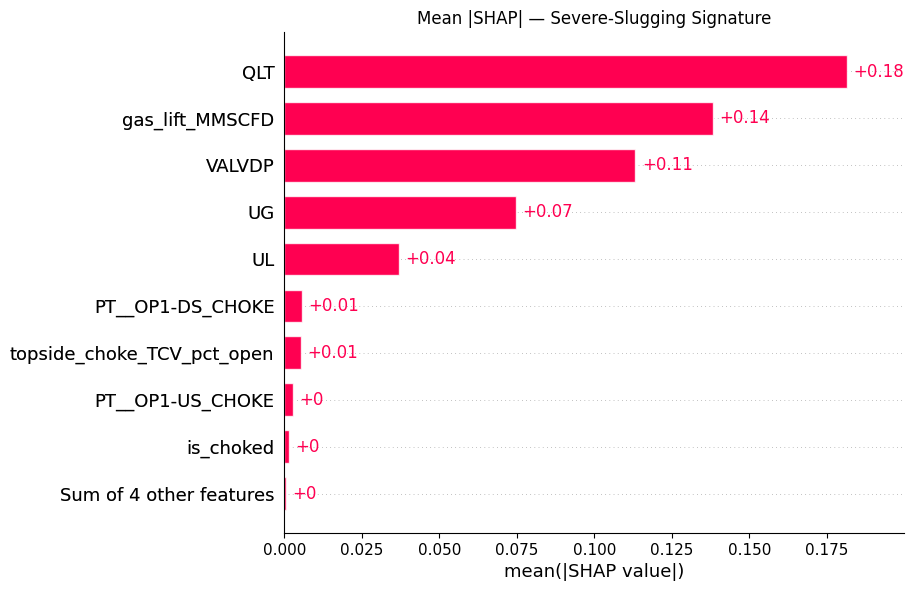

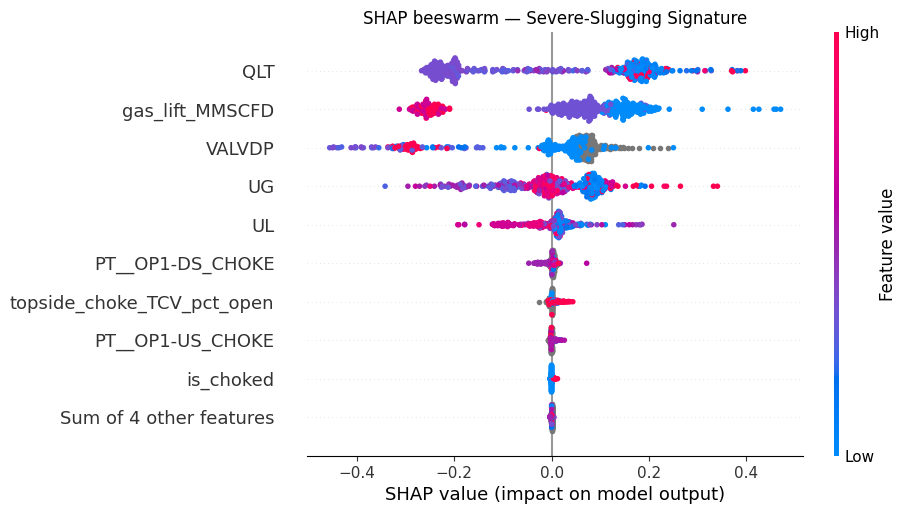

In [19]:
#SHAP Integration - Step 5
sev = classes.index('Severe-Slugging Signature')

shap.plots.bar(expl[:, :, sev], show=False)
plt.title('Mean |SHAP| — Severe-Slugging Signature'); plt.show()

shap.plots.beeswarm(expl[:, :, sev], show=False)
plt.title('SHAP beeswarm — Severe-Slugging Signature'); plt.show()

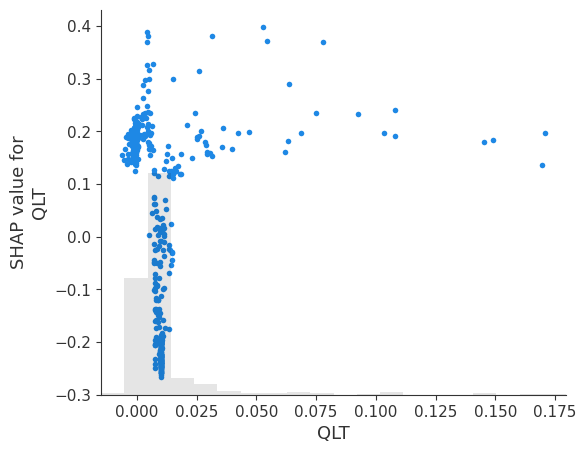

In [20]:
shap.plots.scatter(expl[:, 'QLT', sev])

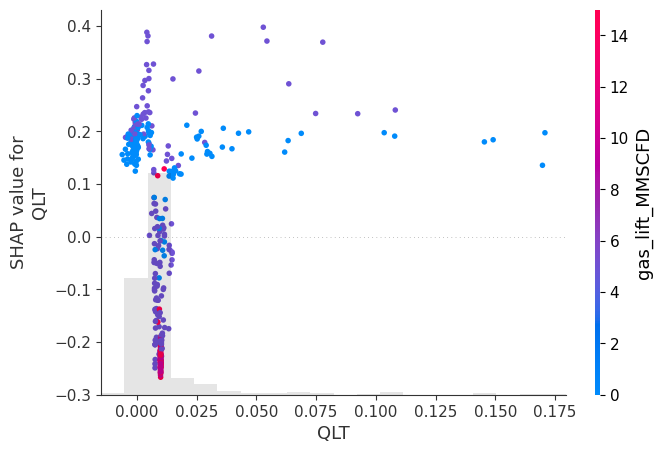

In [21]:
shap.plots.scatter(expl[:, 'QLT', sev], color=expl[:, 'gas_lift_MMSCFD', sev])

In [22]:
#SHAP Integration - Step 6
abs_sev = pd.DataFrame(np.abs(expl.values[:, :, sev]), columns=X_cols)
abs_sev['scenario'] = meta_all['scenario_id'].iloc[sample_idx].values
print(abs_sev.groupby('scenario').mean().round(3))

            QLT     UL     UG  VALVDP  PT__OP1-US_CHOKE  PT__OP1-DS_CHOKE  well_branch  gas_lift_MMSCFD  topside_choke_TCV_pct_open  is_choked  choke_pct_open  pressure_drop  has_pressure_data
scenario                                                                                                                                                                                        
SC01      0.235  0.100  0.017   0.077             0.002             0.003          0.0            0.258                       0.004      0.001             0.0          0.000                0.0
SC02      0.187  0.042  0.093   0.105             0.001             0.001          0.0            0.090                       0.002      0.001             0.0          0.000                0.0
SC03      0.165  0.016  0.068   0.062             0.000             0.006          0.0            0.163                       0.001      0.000             0.0          0.000                0.0
SC04      0.149  0.018  0.058   0.0

Scenario: SC01 | Time: 26.7502918243408 | Predicted: Stable / Continuous Flow


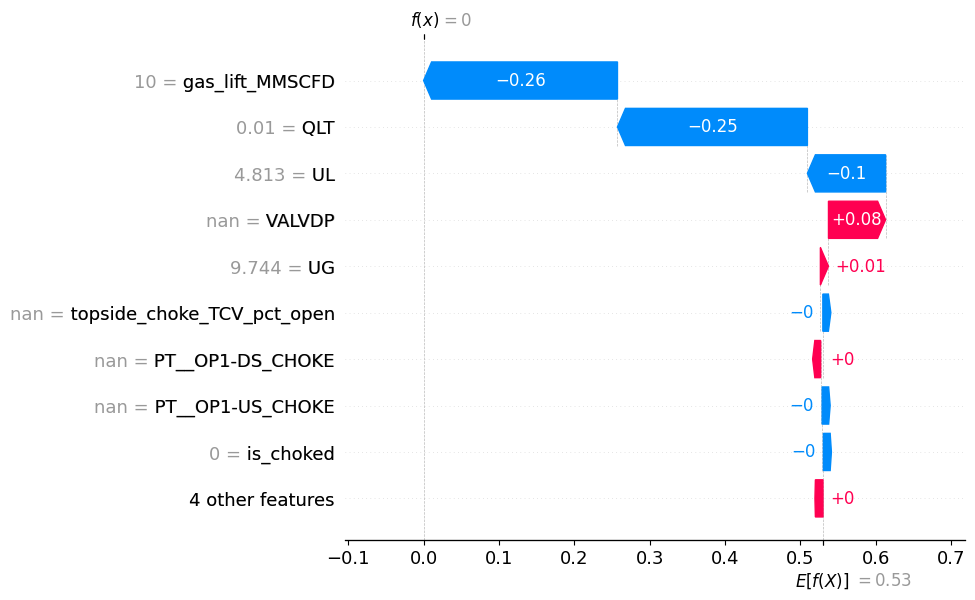

In [23]:
#SHAP Integration - Step 7
i = 0   # change to any row index in X_explain
print("Scenario:", meta_all['scenario_id'].iloc[sample_idx[i]],
      "| Time:", meta_all['TIME_h'].iloc[sample_idx[i]],
      "| Predicted:", classes[pred[i].argmax()])
shap.plots.waterfall(expl[i, :, sev])

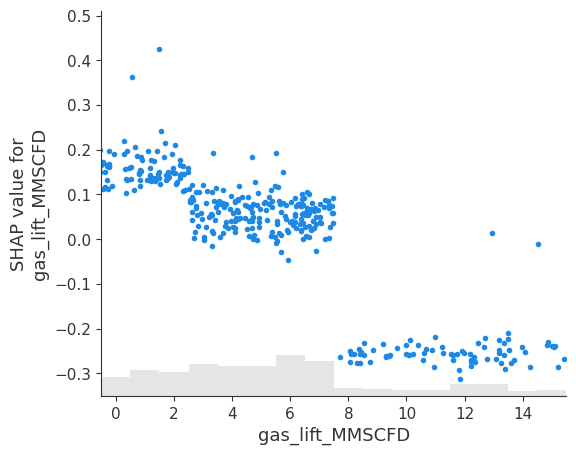

In [24]:
#SHAP Integration - Step 8
shap.plots.scatter(expl[:, 'gas_lift_MMSCFD', sev])

### Reading the importance table

- If `label_mode` is `heuristic_proxy`: importance here tells you what instantaneous signals
  (raw `QLT`, `UG`, `gas_lift_MMSCFD`, `VALVDP`, etc.) the model leans on — rolling-window
  features are deliberately excluded from `X_cols` for this label mode, so you won't see the
  self-referential leakage found earlier in this project.
- If `label_mode` is `olga_native`: all engineered features (including rolling statistics) are
  available and legitimate to interpret physically, since the label no longer shares a formula
  with any predictor.

## 8. Download the trained model

Grabs `slugging_model.joblib` to your local machine. Reload it later (in a fresh Colab session
or elsewhere) with:

```python
import joblib
bundle = joblib.load('slugging_model.joblib')
clf = bundle['model']
feature_columns = bundle['feature_columns']
label_mode = bundle['label_mode']
```


In [25]:
from google.colab import files
files.download('slugging_model.joblib')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**EXPERIMENTS**

In [26]:
# Threshold Sensitivity

import features, itertools, pandas as pd

rows = []
for w, thr in itertools.product([6, 9, 12], [0.7, 1.0, 1.3]):
    features.HEURISTIC_AMP_SEVERE = thr
    for sid, g in master.groupby('scenario_id'):
        g = g.sort_values('TIME_h')
        _, _, lbl = features.build_heuristic_label(g, window=w)
        rows.append({'window': w, 'amp_severe': thr, 'scenario': sid,
                     'pct_severe': round((lbl == 'Severe-Slugging Signature').mean() * 100, 1)})
features.HEURISTIC_AMP_SEVERE = 1.0   # restore the original value

print(pd.DataFrame(rows).pivot_table(index='scenario',
                                     columns=['window', 'amp_severe'],
                                     values='pct_severe'))

window         6                  9                    12              
amp_severe    0.7   1.0   1.3    0.7    1.0    1.3    0.7    1.0    1.3
scenario                                                               
SC01          1.4   1.4   0.0    1.7    1.7    0.0    2.4    2.4    0.0
SC02         94.1  89.3  82.0   95.8   94.1   93.1   96.9   94.5   93.4
SC03        100.0  99.7  99.3  100.0  100.0  100.0  100.0  100.0  100.0
SC04        100.0  99.7  99.7  100.0  100.0  100.0  100.0  100.0  100.0
SC05          1.4   1.4   0.0    1.7    1.7    0.0    2.4    2.4    0.0
SC06         81.3  74.7  70.6   95.8   88.9   83.0  100.0   95.8   91.7
SC07         34.6   2.1   1.7   40.8    3.1    2.8   47.1    3.8    3.5
SC08          5.2   4.5   3.1    5.5    5.5    4.2    6.2    6.2    4.8
SC09        100.0  99.7  99.7  100.0  100.0  100.0  100.0  100.0  100.0


PermutationExplainer explainer: 451it [17:40,  2.37s/it]


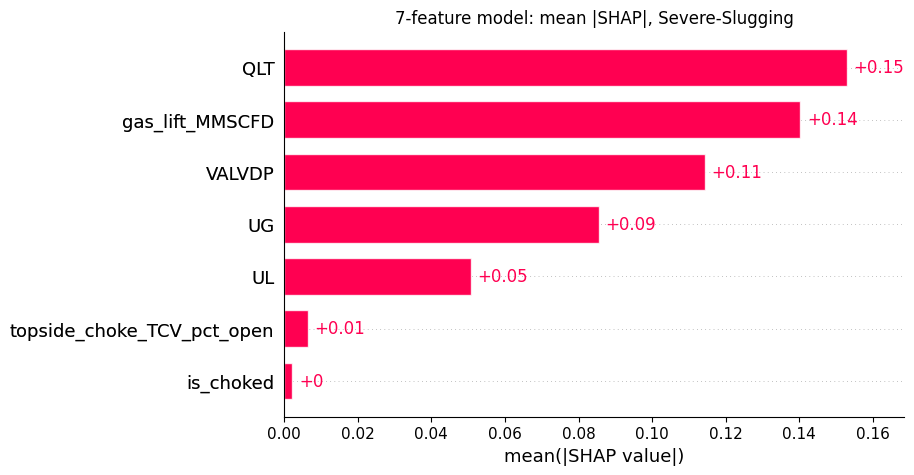

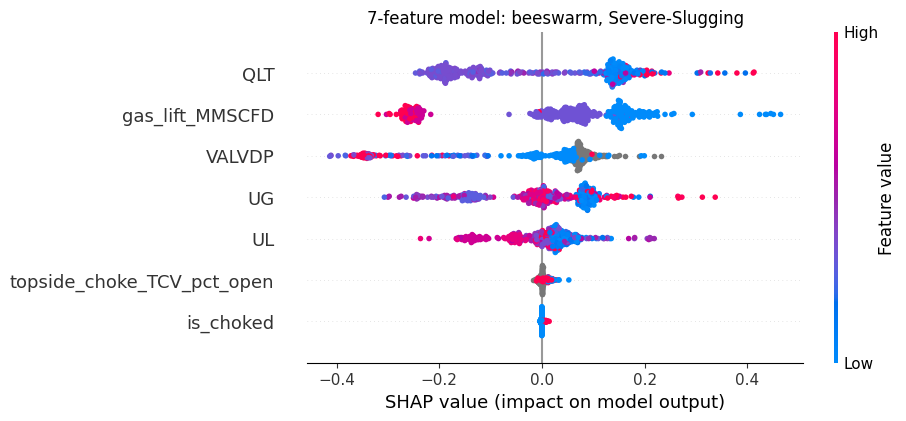

In [27]:
#Using 7 features only

import numpy as np, pandas as pd, shap
import matplotlib.pyplot as plt
from model import fit_final_model, encode_categoricals

X_cols_7 = ['QLT', 'UL', 'UG', 'VALVDP', 'gas_lift_MMSCFD',
            'topside_choke_TCV_pct_open', 'is_choked']

model_7 = fit_final_model(feat, X_cols_7, y)
X7 = encode_categoricals(feat[X_cols_7]).reset_index(drop=True)

rng = np.random.default_rng(42)
scen = feat['scenario_id'].reset_index(drop=True)
idx7 = np.concatenate([rng.choice(np.where(scen == s)[0], 50, replace=False)
                       for s in scen.unique()])
bg7 = shap.sample(X7, 100, random_state=42)

explainer7 = shap.Explainer(model_7.predict_proba, bg7, algorithm='permutation',
                            output_names=list(model_7.classes_))
expl7 = explainer7(X7.iloc[idx7])
sev7 = list(model_7.classes_).index('Severe-Slugging Signature')

shap.plots.bar(expl7[:, :, sev7], show=False)
plt.title('7-feature model: mean |SHAP|, Severe-Slugging'); plt.show()
shap.plots.beeswarm(expl7[:, :, sev7], show=False)
plt.title('7-feature model: beeswarm, Severe-Slugging'); plt.show()

In [28]:
# How much real class mixing is left

import numpy as np, pandas as pd

d = pd.DataFrame({'scenario': feat['scenario_id'].values,
                  'time_h': feat['TIME_h'].values,
                  'label': np.asarray(y)})

rows = []
for cutoff in [0, 1.1, 2.1, 4.1]:          # drop rows with time <= cutoff hours
    sub = d[d['time_h'] >= cutoff]
    for sid, g in sub.groupby('scenario'):
        counts = g['label'].value_counts()
        rows.append({'drop_before_h': cutoff, 'scenario': sid,
                     'minority_rows': int(len(g) - counts.iloc[0])})

print(pd.DataFrame(rows).pivot(index='scenario', columns='drop_before_h',
                               values='minority_rows'))

drop_before_h  0.0  1.1  2.1  4.1
scenario                         
SC01             6    1    0    0
SC02            17   12    8    0
SC03             0    0    0    0
SC04             0    0    0    0
SC05             8    3    0    0
SC06            32   31   27   24
SC07             9    4    0    0
SC08            31   26   22   14
SC09             0    0    0    0


**Final Test Results**


=== rows with time >= 0 h ===

scenario                          dominant                            HistGB  HistGB_row_acc%                            LogReg  LogReg_row_acc%
    SC01          Stable / Continuous Flow         Severe-Slugging Signature              1.4          Stable / Continuous Flow             97.9
    SC02         Severe-Slugging Signature         Severe-Slugging Signature             90.7         Severe-Slugging Signature             94.1
    SC03         Severe-Slugging Signature         Severe-Slugging Signature            100.0         Severe-Slugging Signature            100.0
    SC04         Severe-Slugging Signature         Severe-Slugging Signature            100.0         Severe-Slugging Signature             99.0
    SC05          Stable / Continuous Flow         Severe-Slugging Signature              1.7          Stable / Continuous Flow             97.2
    SC06         Severe-Slugging Signature         Severe-Slugging Signature             87.9         Severe-Slugging Signature             82.4
    SC07 Transitional / Mildly Oscillatory         Severe-Slugging Signature             20.1         Severe-Slugging Signature             10.4
    SC08          Stable / Continuous Flow Transitional / Mildly Oscillatory              6.9 Transitional / Mildly Oscillatory              6.6
    SC09         Severe-Slugging Signature         Severe-Slugging Signature            100.0         Severe-Slugging Signature            100.0
HistGB dominant class right for 5 of 9
LogReg dominant class right for 7 of 9

=== rows with time >= 4.1 h ===
scenario                          dominant                            HistGB  HistGB_row_acc%                            LogReg  LogReg_row_acc%
    SC01          Stable / Continuous Flow         Severe-Slugging Signature              0.0         Severe-Slugging Signature              0.0
    SC02         Severe-Slugging Signature         Severe-Slugging Signature             93.0         Severe-Slugging Signature            100.0
    SC03         Severe-Slugging Signature         Severe-Slugging Signature            100.0         Severe-Slugging Signature            100.0
    SC04         Severe-Slugging Signature         Severe-Slugging Signature            100.0         Severe-Slugging Signature            100.0
    SC05          Stable / Continuous Flow         Severe-Slugging Signature              0.0          Stable / Continuous Flow            100.0
    SC06         Severe-Slugging Signature         Severe-Slugging Signature             88.2         Severe-Slugging Signature             88.6
    SC07 Transitional / Mildly Oscillatory         Severe-Slugging Signature             19.9 Transitional / Mildly Oscillatory            100.0
    SC08          Stable / Continuous Flow Transitional / Mildly Oscillatory              5.1 Transitional / Mildly Oscillatory              5.1
    SC09         Severe-Slugging Signature         Severe-Slugging Signature             98.9         Severe-Slugging Signature            100.0
HistGB dominant class right for 5 of 9
LogReg dominant class right for 7 of 9


In [29]:
#Last test

import numpy as np, pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

models = {
    'HistGB': HistGradientBoostingClassifier(random_state=42, max_iter=200),
    'LogReg': Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                        ('sc', StandardScaler()),
                        ('lr', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
}
base = feat[['scenario_id', 'TIME_h'] + X_cols_7].copy()
base['label'] = np.asarray(y)

def scenario_level(min_t):
    d = base[base['TIME_h'] >= min_t].reset_index(drop=True)
    X, lab, s = d[X_cols_7], d['label'], d['scenario_id']
    dom = lab.groupby(s).agg(lambda v: v.value_counts().index[0])
    rows = []
    for held in s.unique():
        tr, te = s != held, s == held
        r = {'scenario': held, 'dominant': dom[held]}
        for n, m in models.items():
            p = pd.Series(clone(m).fit(X[tr], lab[tr]).predict(X[te]))
            r[n] = p.value_counts().index[0]
            r[n + '_row_acc%'] = round((p.values == lab[te].values).mean() * 100, 1)
        rows.append(r)
    out = pd.DataFrame(rows)
    print(f'\n=== rows with time >= {min_t} h ===')
    print(out.to_string(index=False))
    for n in models:
        print(n, 'dominant class right for', int((out[n] == out['dominant']).sum()), 'of', len(out))

for mt in [0, 4.1]:
    scenario_level(mt)


=== rows with time >= 0 h ===
scenario                          dominant                            HistGB  HistGB_row_acc%                            LogReg  LogReg_row_acc%
    SC01          Stable / Continuous Flow         Severe-Slugging Signature              1.4          Stable / Continuous Flow             97.9
    SC02         Severe-Slugging Signature         Severe-Slugging Signature             90.7         Severe-Slugging Signature             94.1
    SC03         Severe-Slugging Signature         Severe-Slugging Signature            100.0         Severe-Slugging Signature            100.0
    SC04         Severe-Slugging Signature         Severe-Slugging Signature            100.0         Severe-Slugging Signature             99.0
    SC05          Stable / Continuous Flow         Severe-Slugging Signature              1.7          Stable / Continuous Flow             97.2
    SC06         Severe-Slugging Signature         Severe-Slugging Signature             87.9      

## 9. Re-running with expanded data

To retrain once you have more OLGA scenarios (and ideally a real `ID` export):

1. Add the new `.xlsx` workbooks to `DATA_DIR` (re-run the upload cell, or drop them into the
   Drive folder).
2. **Re-run this notebook from Section 4 onward** — nothing else needs to change. The
   consolidation step will auto-detect and quality-check the new scenarios, the feature step will
   auto-switch to the real `ID` label the moment one is present, and the LOSO evaluation will use
   however many scenarios (groups) you now have.
3. Once you're above roughly 20-30 scenarios with real labels, consider re-enabling rolling-window
   features explicitly and re-examining the LOSO multi-class accuracy — that's the point at which
   this project's modelling plan anticipated moving from "pipeline validation" to a genuinely
   reportable predictive result.
